# Poisson Equation

## Problem
$$
-(u_{xx} + u_{yy}) = 2\pi^2 \sin(\pi x)\sin(\pi y), \quad u = 0 \text{ on the boundary}
$$
Exact solution $u = \sin(\pi x)\sin(\pi y)$.

## Discretization
The five-point stencil gives $A u = b$ with

$$
A = \frac{1}{h^2}\left(I \otimes T + T \otimes I\right), \quad T = \text{tridiag}(-1, 2, -1)
$$

built with `scipy.sparse` and solved with `spsolve`.

## Code

In [1]:
import sys
sys.path.append('../src')
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from elliptic import lap_matrix, poisson

In [2]:
f = lambda X, Y: 2*np.pi**2*np.sin(np.pi*X)*np.sin(np.pi*Y)
ex = lambda X, Y: np.sin(np.pi*X)*np.sin(np.pi*Y)

### Sparsity

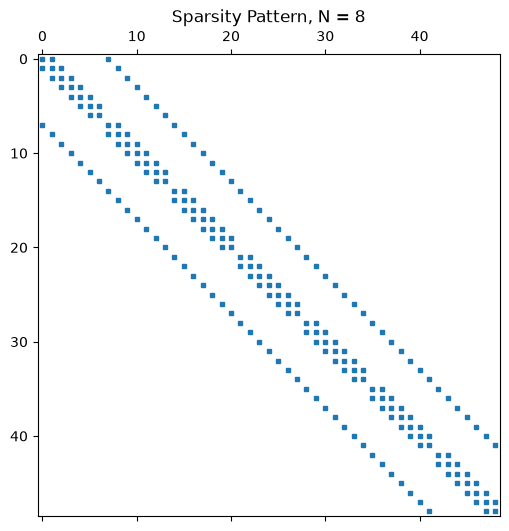

In [3]:
A = lap_matrix(8)
plt.figure(figsize=(6, 6))
plt.spy(A, markersize=3)
plt.title("Sparsity Pattern, N = 8")
plt.savefig("../figures/04_spy.png", dpi=300, bbox_inches="tight")
plt.show()

In [4]:
sp_rows = []
for N in [8, 16, 32, 64]:
    A = lap_matrix(N)
    sp_rows.append({'N': N, 'nnz': A.nnz, 'N2': (N-1)**2, 'N4': (N-1)**4})
sp = pd.DataFrame(sp_rows)
sp

,N,nnz,N2,N4
0,8,217,49,2401
1,16,1065,225,50625
2,32,4681,961,923521
3,64,19593,3969,15752961


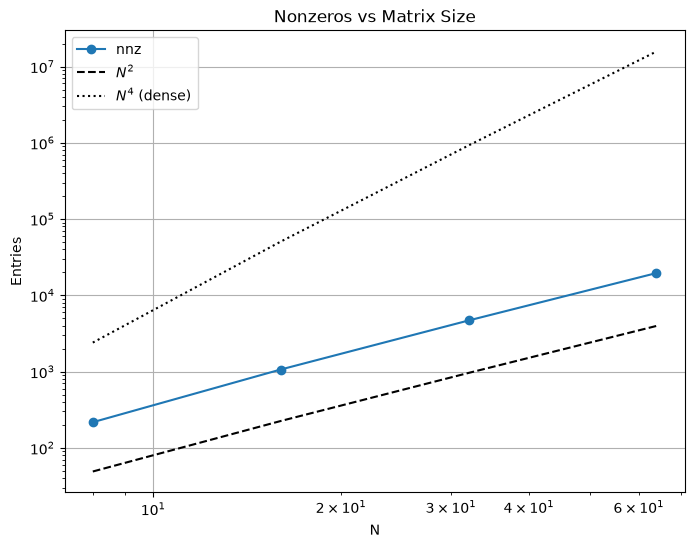

In [5]:
plt.figure(figsize=(8, 6))
plt.loglog(sp['N'], sp['nnz'], 'o-', label="nnz")
plt.loglog(sp['N'], sp['N2'], 'k--', label=r"$N^2$")
plt.loglog(sp['N'], sp['N4'], 'k:', label=r"$N^4$ (dense)")
plt.xlabel("N")
plt.ylabel("Entries")
plt.title("Nonzeros vs Matrix Size")
plt.legend()
plt.grid(True)
plt.savefig("../figures/04_nnz.png", dpi=300, bbox_inches="tight")
plt.show()

### Convergence

In [6]:
results = []
for N in [8, 16, 32, 64]:
    x, u = poisson(N, f)
    X, Y = np.meshgrid(x, x, indexing='ij')
    results.append({'h': 1/N, 'err': np.linalg.norm((u-ex(X, Y)).ravel(), np.inf)})
df = pd.DataFrame(results)
df['order'] = np.log2(df['err'].shift()/df['err'])
df

,h,err,order
0,0.125000,0.012951,NaN
1,0.062500,0.003219,2.008367
2,0.031250,0.000804,2.002087
3,0.015625,0.000201,2.000522


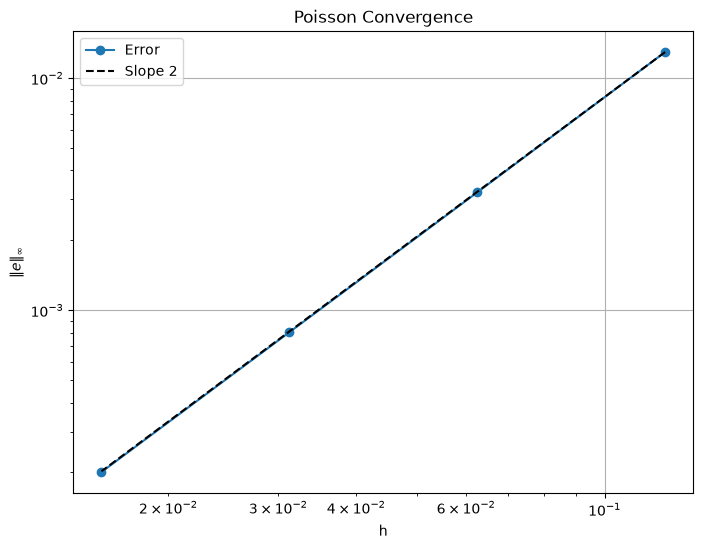

In [7]:
h = df['h'].values
plt.figure(figsize=(8, 6))
plt.loglog(h, df['err'], 'o-', label="Error")
plt.loglog(h, df['err'][0]*(h/h[0])**2, 'k--', label="Slope 2")
plt.xlabel("h")
plt.ylabel(r"$\|e\|_\infty$")
plt.title("Poisson Convergence")
plt.legend()
plt.grid(True)
plt.savefig("../figures/04_convergence.png", dpi=300, bbox_inches="tight")
plt.show()

### Solution

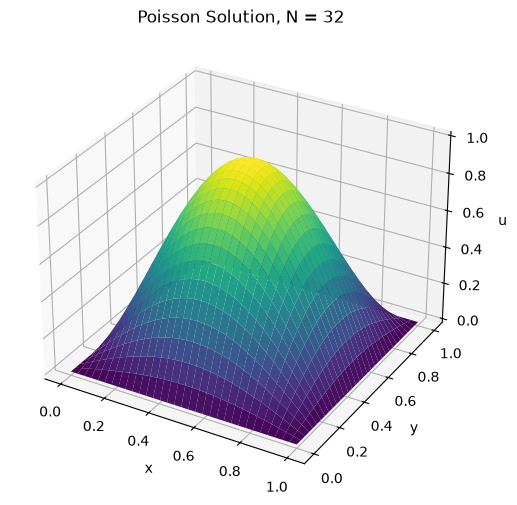

In [8]:
x, u = poisson(32, f)
X, Y = np.meshgrid(x, x, indexing='ij')
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection='3d')
ax.plot_surface(X, Y, u, cmap='viridis')
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("u")
plt.title("Poisson Solution, N = 32")
# plt.tight_layout()
plt.savefig("../figures/04_surface.png", dpi=300, bbox_inches="tight")
plt.show()

## Conclusion
The error is O(h^2) and each row of A has at most 5 nonzeros, so nnz grows like N^2 and not N^4. At N = 64 that is 19593 entries against 15.7 million for a dense matrix.